## Task 1: Data Preparation and Feature Engineering

# 1.1 Ticker selection and data acquisition

Install and Import Libraries

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import scipy, sklearn

from datetime import datetime, timezone
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Study Period
start = '2021-01-01'
end = '2025-01-01'

Extract the current S&P 500 constituent list from Wikipedia

In [2]:
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})

sp500_df = table[0]

retrieval_date = datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M UTC')

Convert ticker symbols to Yahoo Finance format

In [3]:
sp500_df['Ticker'] = sp500_df['Symbol'].str.replace('.', '-', regex=False)
tickers = sp500_df['Ticker'].tolist()

Save a snapshot of the constituent list

In [4]:
sp500_df.to_csv('sp500_constituents.csv', index=False)
print('Retrieval date:', retrieval_date)
print('Total tickers extracted:', len(tickers))

Retrieval date: 2026-11-24 11:01 UTC
Total tickers extracted: 503


Preview the first 10 companies

In [5]:
sp500_df[['Symbol', 'Security', 'GICS Sector']].head(10)

,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


Downloading daily market data for all S&P 500 constituents

In [6]:
data = yf.download(tickers, start=start, end=end, auto_adjust=False, actions=True)
adj_close = data['Adj Close']
close = data['Close']
volume = data['Volume']
splits = data['Stock Splits']

benchmark = yf.download('^GSPC', start=start, end=end, auto_adjust=False)['Adj Close'].squeeze()

[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['Q', 'FDXF', 'SNDK', 'HONA', 'VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
[*********************100%***********************]  1 of 1 completed


Saving data snapshots

In [7]:
adj_close.to_csv('adj_close.csv'); close.to_csv('close.csv'); volume.to_csv('volume.csv')
splits.to_csv('splits.csv'); benchmark.to_csv('benchmark_gspc.csv')

print('Share data:', adj_close.shape, '| Benchmark:', benchmark.shape)
print('Dates:', benchmark.index.min().date(), 'to', benchmark.index.max().date())

Share data: (1005, 503) | Benchmark: (1005,)
Dates: 2021-01-04 to 2024-12-31


# 1.2 Data validation and alignment

Align Share Data to the Benchmark Trading Calendar

In [8]:
trading_days = benchmark.dropna().index

adj_close = adj_close.reindex(columns=tickers).reindex(trading_days)
close = close.reindex(columns=tickers).reindex(trading_days)
volume = volume.reindex(columns=tickers).reindex(trading_days)

Check for Duplicate Trading Dates

In [9]:
print("Duplicate dates (shares):", data.index.duplicated().sum())
print("Duplicate dates (benchmark):", benchmark.index.duplicated().sum())

Duplicate dates (shares): 0
Duplicate dates (benchmark): 0


Validate Data Quality

In [10]:
checks = pd.DataFrame(index=tickers)

checks['missing_adj_close'] = adj_close.isna().sum()
checks['missing_close'] = close.isna().sum()
checks['missing_volume'] = volume.isna().sum()

checks['nonpositive_price'] = ((adj_close <= 0).sum() + (close <= 0).sum())

checks['zero_or_negative_volume'] = (volume <= 0).sum()

Check Trading History and Corporate Actions

In [11]:
checks['first_date'] = adj_close.apply(lambda s: s.first_valid_index())
checks['last_date'] = adj_close.apply(lambda s: s.last_valid_index())

# Count stock split events
checks['split_events'] = (
    splits.reindex(columns=tickers)
          .fillna(0)
          .gt(0)
          .sum()
)

Identify Invalid Shares

In [12]:
def exclusion_reason(row):

    if pd.isna(row['first_date']):
        return 'No price data'

    if row['first_date'] > trading_days[0]:
        return f"History starts {row['first_date'].date()}"

    if row['last_date'] < trading_days[-1]:
        return f"History ends {row['last_date'].date()}"

    if row[['missing_adj_close',
            'missing_close',
            'missing_volume']].max() > 0:
        return 'Missing values inside the period'

    if row['nonpositive_price'] > 0:
        return 'Non-positive prices'

    if row['zero_or_negative_volume'] > 0:
        return 'Zero or negative volume'

    return ''

checks['reason'] = checks.apply(exclusion_reason, axis=1)

Generate the Exclusion Log

In [13]:
exclusion_log = (
    checks.loc[checks['reason'] != '', ['reason']]
    .join(sp500_df.set_index('Ticker')[['Security']])
)

valid = checks.index[checks['reason'] == ''].tolist()

print("Valid shares:", len(valid))
print("Excluded shares:", len(exclusion_log))

exclusion_log

Valid shares: 486
Excluded shares: 17


,reason,Security
APP,History starts 2021-04-15,AppLovin
COIN,History starts 2021-04-14,Coinbase
CEG,History starts 2022-01-19,Constellation Energy
EXE,History starts 2021-02-10,Expand Energy
FDXF,No price data,FedEx Freight
FERG,Zero or negative volume,Ferguson Enterprises
GEHC,History starts 2022-12-15,GE HealthCare
GEV,History starts 2024-03-27,GE Vernova
HONA,No price data,Honeywell Aerospace
Q,No price data,Qnity Electronics


Retain Valid Shares

In [14]:
adj_close = adj_close[valid]
close = close[valid]
volume = volume[valid]
splits = splits[valid]

Validate Corporate Actions

In [15]:
close_change = close.pct_change(fill_method=None)

# Review stock split events
split_list = splits.stack()
split_list = split_list[split_list > 0].reset_index()
split_list.columns = ['Date', 'Ticker', 'Split_ratio']

split_list['Close_change_on_date'] = [
    close_change.loc[d, t]
    for d, t in zip(split_list['Date'], split_list['Ticker'])
]

split_list

,Date,Ticker,Split_ratio,Close_change_on_date
0,2021-03-05,APH,2.000,0.025316
1,2021-04-01,SHW,3.000,0.015230
2,2021-06-03,MRK,1.048,0.020926
3,2021-06-28,CSGP,10.000,-0.037897
4,2021-06-29,CSX,3.000,-0.006714
...,...,...,...,...
56,2024-10-03,LRCX,10.000,-0.003673
57,2024-12-04,ANET,4.000,0.017517
58,2024-12-13,ETR,2.000,0.001416
59,2024-12-16,PANW,2.000,0.030220


Check for Unusual Daily Price Movements

In [16]:
large_moves = close_change.stack()

large_moves[large_moves.abs() > 0.40]

,,0
Date,Ticker,
2022-08-05,CVNA,0.400716
2022-12-07,CVNA,-0.429210
2023-01-12,CVNA,0.460000
2023-06-08,CVNA,0.560206
2023-07-19,CVNA,0.402010
2024-04-11,GL,-0.531402
2024-07-26,DXCM,-0.406583
2024-11-15,BE,0.591867


# 1.3 Weekly return and weekly beta

Mean weekly return

In [17]:
def calculate_weekly_returns(prices):
    """Calculate Friday-ending weekly returns from daily adjusted closing prices."""

    weekly_prices = prices.resample('W-FRI').last()

    # Exclude incomplete first and final calendar weeks
    complete = (
        (weekly_prices.index - pd.Timedelta(days=4) >= pd.Timestamp(start))
        & (weekly_prices.index < pd.Timestamp(end))
    )

    weekly_prices = weekly_prices[complete]

    return weekly_prices.pct_change(fill_method=None).iloc[1:]

Calculate Weekly Returns for Shares and Benchmark

In [18]:
# Calculate weekly returns
weekly_returns = calculate_weekly_returns(adj_close)
market_weekly_returns = calculate_weekly_returns(benchmark)

Validate Weekly Alignment

In [19]:
print("Same week labels:",
      weekly_returns.index.equals(market_weekly_returns.index))

print(
    "Weeks:",
    len(weekly_returns),
    "|",
    weekly_returns.index[0].date(),
    "to",
    weekly_returns.index[-1].date()
)

print(
    "Missing weekly returns:",
    weekly_returns.isna().sum().sum()
)

Same week labels: True
Weeks: 207 | 2021-01-15 to 2024-12-27
Missing weekly returns: 0


Calculate the Mean Weekly Return

In [20]:
mean_weekly_return = (
    weekly_returns.mean()
    .rename("Mean_Weekly_Return")
)

mean_weekly_return.describe()

,Mean_Weekly_Return
count,486.000000
mean,0.002857
std,0.002652
min,-0.004468
25%,0.001182
50%,0.002619
75%,0.004207
max,0.017772


Calculate Weekly Beta

In [21]:
def calculate_weekly_beta(weekly_returns, market_returns):

    results = []

    for share in weekly_returns.columns:

        paired = (
            pd.concat(
                [
                    weekly_returns[share].rename("share"),
                    market_returns.rename("market")
                ],
                axis=1
            )
            .dropna()
        )

        beta = (
            paired["share"].cov(paired["market"])
            / paired["market"].var(ddof=1)
        )

        results.append({
            "Share": share,
            "Beta": beta,
            "Paired_weeks": len(paired)
        })

    return pd.DataFrame(results).set_index("Share")

Calculate Weekly Beta for All Shares

In [22]:
beta_df = calculate_weekly_beta(
    weekly_returns,
    market_weekly_returns
)

Validate Weekly Beta Results

In [23]:
print(
    "Aligned weekly observations:",
    beta_df["Paired_weeks"].unique()
)

# Summary statistics
beta_df.describe()

Aligned weekly observations: [207]


,Beta,Paired_weeks
count,486.000000,486.0
mean,0.973695,207.0
std,0.407339,0.0
min,0.055452,207.0
25%,0.666599,207.0
50%,0.950610,207.0
75%,1.179538,207.0
max,3.778560,207.0


# 1.4 Adapted RFM Calculations

In [24]:
# Observation date: final common completed trading date
observation_date = close[valid].dropna().index.max()
close_v = close.loc[:observation_date, valid]
volume_v = volume.loc[:observation_date, valid]

# High-volume day: volume > 2 x mean volume of the preceding 20 sessions (current day excluded)
baseline = volume_v.shift(1).rolling(20, min_periods=20).mean()
high_volume = volume_v > 2 * baseline

# Latest 60 trading sessions ending on the observation date
last_60 = close_v.index[-60:]
print('Observation date:', observation_date.date())
print('60-session window:', last_60[0].date(), 'to', last_60[-1].date())
print('20-session baseline available for the whole window:', baseline.loc[last_60].notna().all().all())

Observation date: 2024-12-31
60-session window: 2024-10-07 to 2024-12-31
20-session baseline available for the whole window: True


1.4.1 Recency

In [25]:
last_event = high_volume.apply(lambda s: s[s].index.max() if s.any() else pd.NaT)
recency = (observation_date - last_event).dt.days.rename('Recency')
print('Shares with no high-volume event (Recency missing):', recency.isna().sum())
recency.describe()

Shares with no high-volume event (Recency missing): 0


,Recency
count,486.000000
mean,20.407407
std,21.342438
min,4.000000
25%,11.000000
50%,11.000000
75%,14.750000
max,222.000000


1.4.2 Frequency

In [26]:
frequency = high_volume.loc[last_60].sum().rename('Frequency')
frequency.describe()

,Frequency
count,486.000000
mean,2.989712
std,1.330800
min,0.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,8.000000


1.4.3 Monetary

In [27]:
monetary = (close_v.loc[last_60] * volume_v.loc[last_60]).sum().rename('Monetary')
monetary.describe()

,Monetary
count,4.860000e+02
mean,3.940419e+10
std,1.291388e+11
min,1.297483e+09
25%,1.019517e+10
50%,1.668382e+10
75%,3.227689e+10
max,1.847697e+12


# 1.5 Metric interpretation and supporting evidence

In [28]:
share = 'AAPL'
example = pd.DataFrame({'Close': close_v[share], 'Volume': volume_v[share],
                        'Baseline_20': baseline[share], 'Threshold': 2 * baseline[share],
                        'High_volume': high_volume[share]})
print('Latest high-volume day:', last_event[share].date())
print('Recency =', observation_date.date(), '-', last_event[share].date(), '=', int(recency[share]), 'days')
print('Frequency =', frequency[share], 'high-volume days in the last 60 sessions')
print('Monetary = sum of Close x Volume over 60 sessions = $', f'{monetary[share]:,.0f}')
example.loc[last_60][example.loc[last_60, 'High_volume']]

Latest high-volume day: 2024-12-20
Recency = 2024-12-31 - 2024-12-20 = 11 days
Frequency = 2 high-volume days in the last 60 sessions
Monetary = sum of Close x Volume over 60 sessions = $ 623,303,377,707


,Close,Volume,Baseline_20,Threshold,High_volume
Date,,,,,
2024-11-25,232.869995,90152800,43820740.0,87641480.0,True
2024-12-20,254.490005,147495300,45004605.0,90009210.0,True


Feature table: one row per share

In [29]:
features = (sp500_df.set_index('Ticker')[['Security', 'GICS Sector']].loc[valid]
            .join(mean_weekly_return).join(beta_df)
            .join(last_event.rename('Last_Event')).join(recency).join(frequency).join(monetary))

Shares without a high-volume event are excluded from RFM clustering

In [30]:
no_event = features.index[features['Recency'].isna()]
for t in no_event:
    exclusion_log.loc[t] = ['No high-volume event: Recency missing', features.loc[t, 'Security']]

Common valid share set used for every clustering solution

In [31]:
features = features.dropna(subset=['Mean_Weekly_Return', 'Beta', 'Recency', 'Frequency', 'Monetary'])
print('Common valid share set:', len(features))

features.to_csv('feature_table.csv')
exclusion_log.to_csv('exclusion_log.csv')
features[['Mean_Weekly_Return', 'Beta', 'Recency', 'Frequency', 'Monetary']].describe()

Common valid share set: 486


,Mean_Weekly_Return,Beta,Recency,Frequency,Monetary
count,486.000000,486.000000,486.000000,486.000000,4.860000e+02
mean,0.002857,0.973695,20.407407,2.989712,3.940419e+10
std,0.002652,0.407339,21.342438,1.330800,1.291388e+11
min,-0.004468,0.055452,4.000000,0.000000,1.297483e+09
25%,0.001182,0.666599,11.000000,2.000000,1.019517e+10
50%,0.002619,0.950610,11.000000,3.000000,1.668382e+10
75%,0.004207,1.179538,14.750000,4.000000,3.227689e+10
max,0.017772,3.778560,222.000000,8.000000,1.847697e+12


## Task 2 Stock Segmentation and Sensitivity Analysis

# 2.1 Feature preparation

Create Feature Matrices

In [32]:
risk_return = features[['Mean_Weekly_Return', 'Beta']].copy()

rfm = features[['Recency', 'Frequency', 'Monetary']].copy()

Inspect Feature Skewness

In [33]:
print("Skew before transformation:")

print(
    features[
        ['Mean_Weekly_Return',
         'Beta',
         'Recency',
         'Frequency',
         'Monetary']
    ].skew().round(2)
)

Skew before transformation:
Mean_Weekly_Return     0.87
Beta                   1.10
Recency                3.65
Frequency              0.42
Monetary              11.68
dtype: float64


Reduce Skewness of Monetary

In [34]:
rfm['Monetary'] = np.log1p(rfm['Monetary'])

print("\nSkew after log1p(Monetary):")
print(rfm.skew().round(2))


Skew after log1p(Monetary):
Recency      3.65
Frequency    0.42
Monetary     1.08
dtype: float64


Inspect Feature Distributions

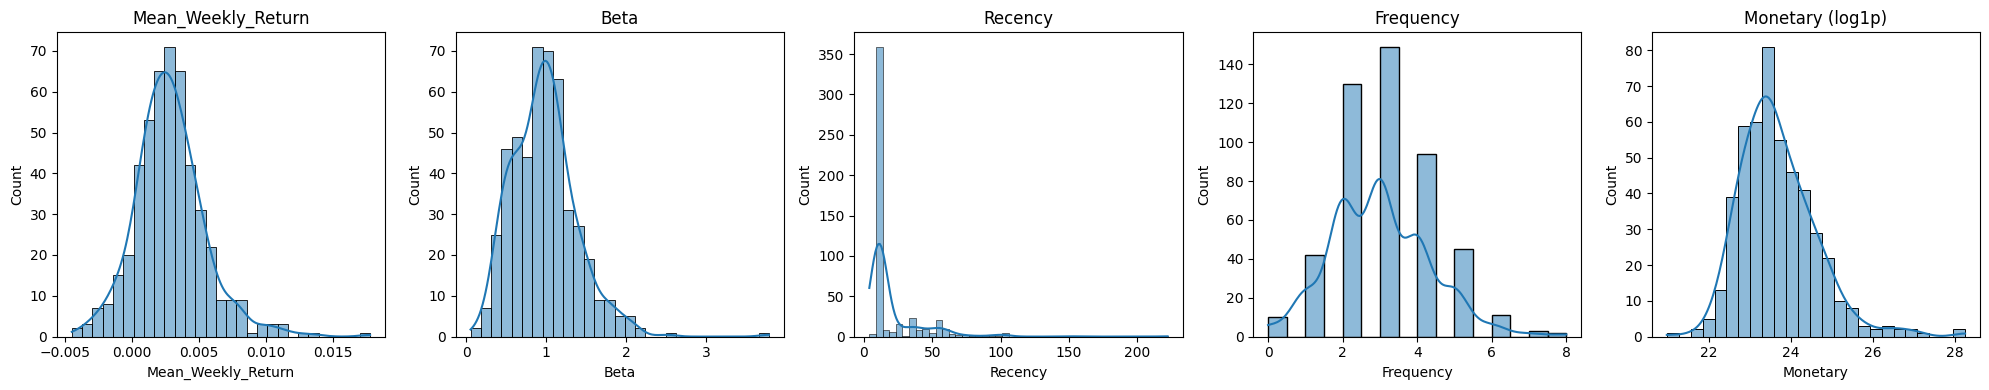

In [35]:
fig, axes = plt.subplots(1, 5, figsize=(20,4))

for ax, col in zip(
    axes,
    ['Mean_Weekly_Return',
     'Beta',
     'Recency',
     'Frequency',
     'Monetary']
):

    data_col = rfm[col] if col in rfm else risk_return[col]

    sns.histplot(data_col, kde=True, ax=ax)

    ax.set_title(
        col + (" (log1p)" if col == "Monetary" else "")
    )

plt.tight_layout()
plt.show()

Inspect Outliers

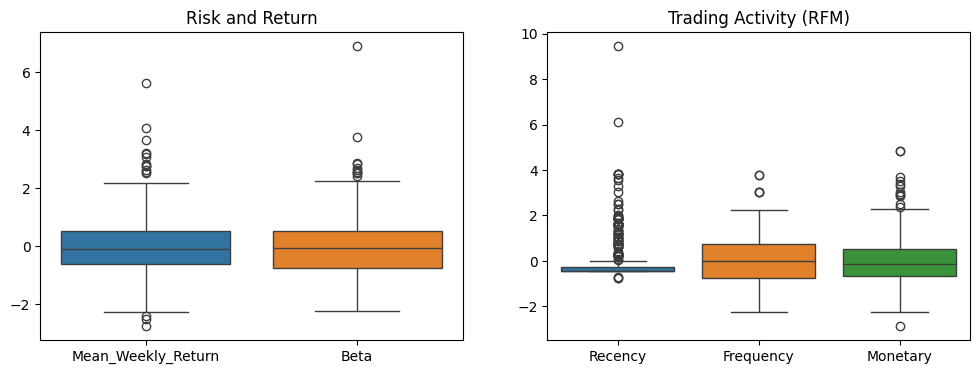

In [36]:
fig, axes = plt.subplots(1,2, figsize=(12,4))

sns.boxplot(
    data=(risk_return-risk_return.mean())/risk_return.std(),
    ax=axes[0]
).set_title("Risk and Return")

sns.boxplot(
    data=(rfm-rfm.mean())/rfm.std(),
    ax=axes[1]
).set_title("Trading Activity (RFM)")

plt.show()

Standardise the Features

In [37]:
rr_scaled = StandardScaler().fit_transform(risk_return)

rfm_scaled = StandardScaler().fit_transform(rfm)

print(
    rr_scaled.mean(axis=0).round(2),
    rr_scaled.std(axis=0).round(2)
)

print(
    rfm_scaled.mean(axis=0).round(2),
    rfm_scaled.std(axis=0).round(2)
)

[-0. -0.] [1. 1.]
[-0. -0. -0.] [1. 1. 1.]


## 2.2 Agglomerative clustering

Apply Ward Hierarchical Clustering

In [38]:
rr_hierarchy = linkage(
    rr_scaled,
    method='ward',
    metric='euclidean'
)

rfm_hierarchy = linkage(
    rfm_scaled,
    method='ward',
    metric='euclidean'
)

Visualise the Dendrograms

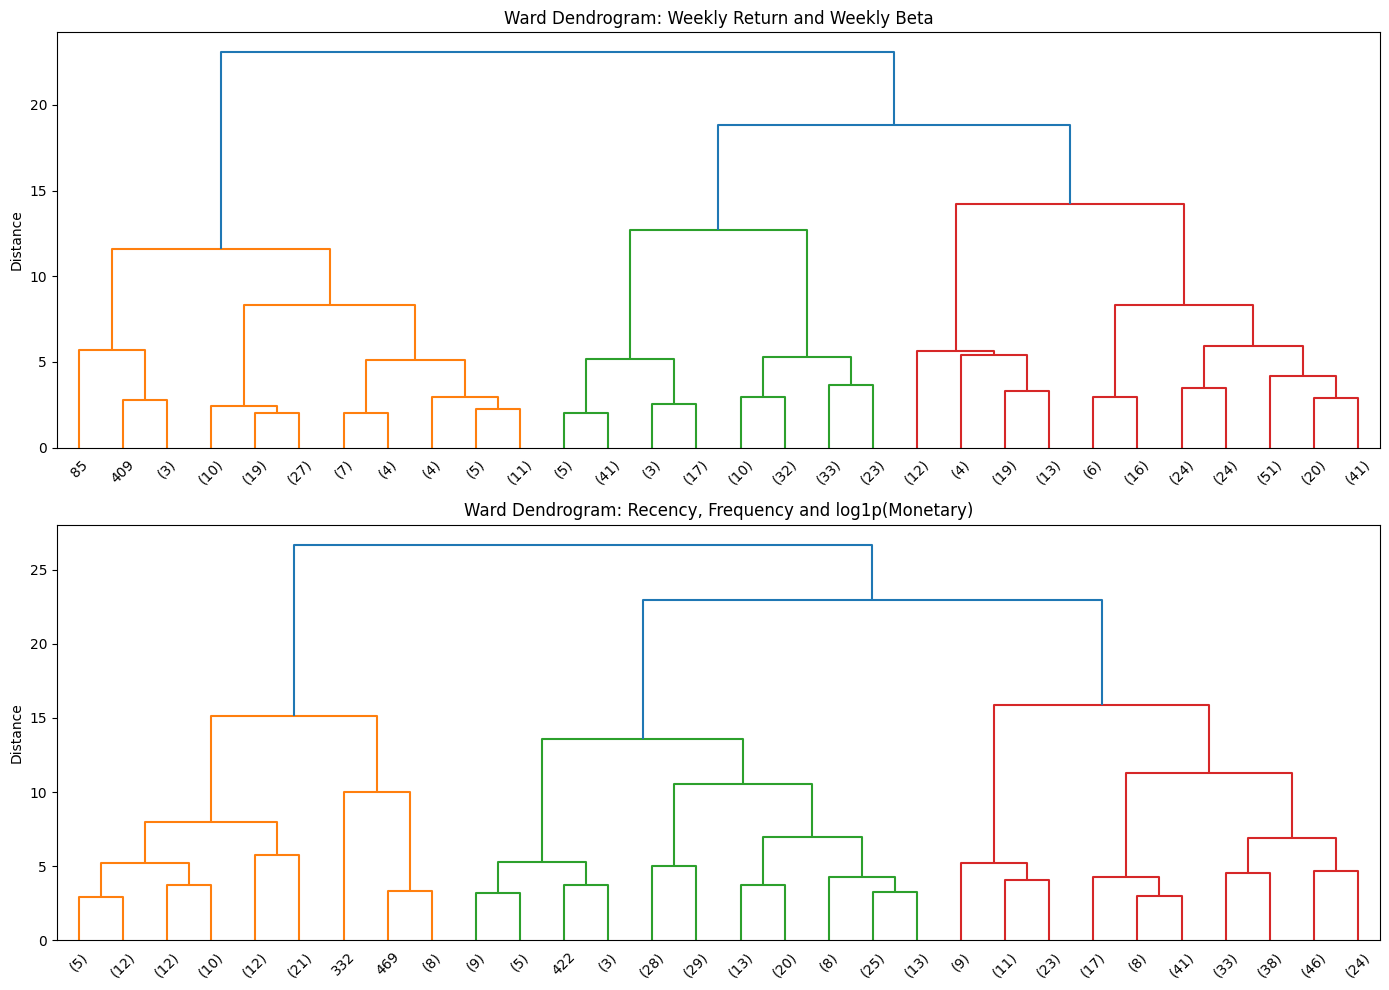

In [39]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

dendrogram(
    rr_hierarchy,
    truncate_mode='lastp',
    p=30,
    ax=axes[0]
)

axes[0].set_title(
    'Ward Dendrogram: Weekly Return and Weekly Beta'
)
axes[0].set_ylabel('Distance')

dendrogram(
    rfm_hierarchy,
    truncate_mode='lastp',
    p=30,
    ax=axes[1]
)

axes[1].set_title(
    'Ward Dendrogram: Recency, Frequency and log1p(Monetary)'
)
axes[1].set_ylabel('Distance')

plt.tight_layout()
plt.show()

Evaluate Candidate Cluster Numbers

In [40]:
def ward_scores(hierarchy, X):

    rows = []

    for k in range(2, 9):

        labels = (
            cut_tree(
                hierarchy,
                n_clusters=k
            )
            .ravel() + 1
        )

        rows.append({
            'k': k,
            'Silhouette': silhouette_score(X, labels),
            'Sizes': np.bincount(labels)[1:].tolist()
        })

    return pd.DataFrame(rows).set_index('k')

Compare Clustering Performance

In [41]:
rr_ward_scores = ward_scores(
    rr_hierarchy,
    rr_scaled
)

rfm_ward_scores = ward_scores(
    rfm_hierarchy,
    rfm_scaled
)

print("Weekly Return and Beta")
print(rr_ward_scores.round(3))

print("\nRFM")
print(rfm_ward_scores.round(3))

Weekly Return and Beta
   Silhouette                             Sizes
k                                              
2       0.339                         [394, 92]
3       0.274                    [230, 164, 92]
4       0.282                [182, 164, 48, 92]
5       0.304             [182, 66, 98, 48, 92]
6       0.320          [182, 66, 98, 48, 87, 5]
7       0.324      [160, 66, 98, 48, 22, 87, 5]
8       0.321  [160, 66, 98, 48, 22, 56, 31, 5]

RFM
   Silhouette                              Sizes
k                                               
2       0.368                          [404, 82]
3       0.304                     [154, 250, 82]
4       0.289                 [154, 207, 82, 43]
5       0.305             [154, 207, 72, 43, 10]
6       0.314         [136, 207, 18, 72, 43, 10]
7       0.292     [136, 66, 18, 72, 141, 43, 10]
8       0.302  [57, 66, 79, 18, 72, 141, 43, 10]


Select the Optimal Number of Clusters

In [42]:
k_rr_ward = rr_ward_scores["Silhouette"].idxmax()

k_rfm_ward = rfm_ward_scores["Silhouette"].idxmax()

Assign Cluster Labels

In [43]:
features["RR_Ward"] = (
    cut_tree(
        rr_hierarchy,
        n_clusters=k_rr_ward
    )
    .ravel() + 1
)

features["RFM_Ward"] = (
    cut_tree(
        rfm_hierarchy,
        n_clusters=k_rfm_ward
    )
    .ravel() + 1
)

Summarise the Selected Clustering Solution

In [44]:
print(
    "Selected k:",
    "Weekly Return and Beta =",
    k_rr_ward,
    "| RFM =",
    k_rfm_ward
)

print("\nRisk & Return cluster sizes")
print(
    features["RR_Ward"]
    .value_counts()
    .sort_index()
)

print("\nRFM cluster sizes")
print(
    features["RFM_Ward"]
    .value_counts()
    .sort_index()
)

Selected k: Weekly Return and Beta = 2 | RFM = 2

Risk & Return cluster sizes
RR_Ward
1    394
2     92
Name: count, dtype: int64

RFM cluster sizes
RFM_Ward
1    404
2     82
Name: count, dtype: int64


## 2.3 K means clustering

Fit K-means Models for Different Cluster Numbers

In [45]:
def kmeans_scores(X):
    rows = []
    for k in range(2, 9):
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans.fit_predict(X)
        rows.append({'k': k, 'Inertia': kmeans.inertia_, 'Silhouette': silhouette_score(X, labels),
                     'Sizes': np.bincount(labels).tolist()})
    return pd.DataFrame(rows).set_index('k')

rr_km_scores = kmeans_scores(rr_scaled)
rfm_km_scores = kmeans_scores(rfm_scaled)
print('Weekly return and beta'); print(rr_km_scores.round(3))
print('\nRFM'); print(rfm_km_scores.round(3))

Weekly return and beta
   Inertia  Silhouette                             Sizes
k                                                       
2  621.634       0.387                        [143, 343]
3  461.185       0.329                   [202, 120, 164]
4  371.577       0.327               [132, 154, 40, 160]
5  309.613       0.341           [112, 166, 131, 27, 50]
6  265.707       0.326        [115, 20, 85, 134, 56, 76]
7  227.476       0.331      [83, 74, 143, 85, 5, 48, 48]
8  195.952       0.353  [143, 81, 82, 5, 77, 36, 34, 28]

RFM
    Inertia  Silhouette                              Sizes
k                                                         
2  1066.832       0.423                          [418, 68]
3   796.674       0.325                     [272, 63, 151]
4   609.834       0.341                 [122, 92, 61, 211]
5   514.714       0.358             [68, 122, 87, 11, 198]
6   437.422       0.346        [104, 120, 141, 69, 11, 41]
7   393.007       0.341     [147, 17, 66, 109,

Compare Candidate Cluster Numbers

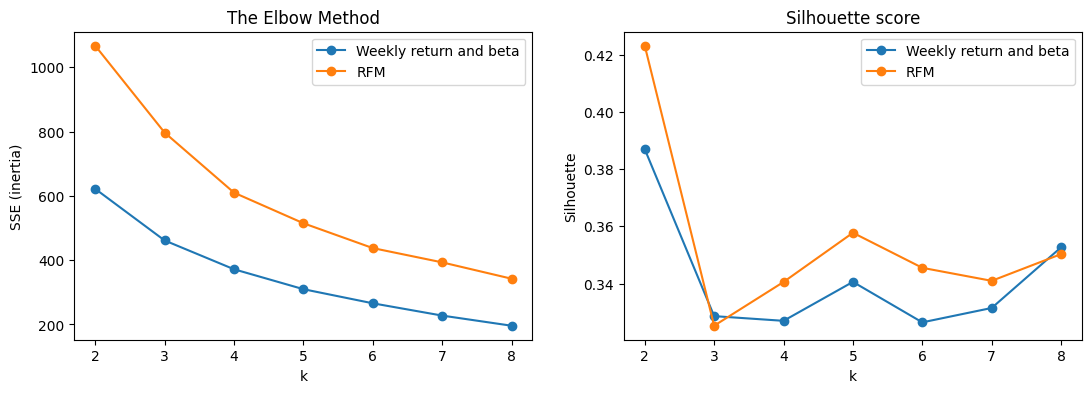

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for scores, name in [(rr_km_scores, 'Weekly return and beta'), (rfm_km_scores, 'RFM')]:
    axes[0].plot(scores.index, scores['Inertia'], marker='o', label=name)
    axes[1].plot(scores.index, scores['Silhouette'], marker='o', label=name)
axes[0].set(title='The Elbow Method', xlabel='k', ylabel='SSE (inertia)')
axes[1].set(title='Silhouette score', xlabel='k', ylabel='Silhouette')
axes[0].legend(); axes[1].legend()
plt.show()

Assign the Selected Cluster Labels

In [47]:
k_rr_km = rr_km_scores['Silhouette'].idxmax()
k_rfm_km = rfm_km_scores['Silhouette'].idxmax()

features['RR_KMeans'] = KMeans(n_clusters=k_rr_km, random_state=42, n_init=10).fit_predict(rr_scaled) + 1
features['RFM_KMeans'] = KMeans(n_clusters=k_rfm_km, random_state=42, n_init=10).fit_predict(rfm_scaled) + 1
print('Selected k: weekly return and beta =', k_rr_km, '| RFM =', k_rfm_km)

Selected k: weekly return and beta = 2 | RFM = 2


## 2.4 Cluster profiles and algorithm comparison

Generate Cluster Profiles

In [48]:
rr_cols = ['Mean_Weekly_Return', 'Beta']
rfm_cols = ['Recency', 'Frequency', 'Monetary']
for col, cols in [('RR_Ward', rr_cols), ('RR_KMeans', rr_cols), ('RFM_Ward', rfm_cols), ('RFM_KMeans', rfm_cols)]:
    profile = features.groupby(col)[cols].mean()
    profile['Count'] = features.groupby(col).size()
    print(col); print(profile.round(4)); print()

RR_Ward
         Mean_Weekly_Return    Beta  Count
RR_Ward                                   
1                    0.0020  0.8979    394
2                    0.0063  1.2981     92

RR_KMeans
           Mean_Weekly_Return    Beta  Count
RR_KMeans                                   
1                      0.0053  1.3505    143
2                      0.0018  0.8166    343

RFM_Ward
          Recency  Frequency      Monetary  Count
RFM_Ward                                         
1         12.7153     3.1708  3.783020e+10    404
2         58.3049     2.0976  4.715898e+10     82

RFM_KMeans
            Recency  Frequency      Monetary  Count
RFM_KMeans                                         
1           13.4234     3.1866  3.269100e+10    418
2           63.3382     1.7794  8.067057e+10     68



Visualise Clusters in Two Dimensions

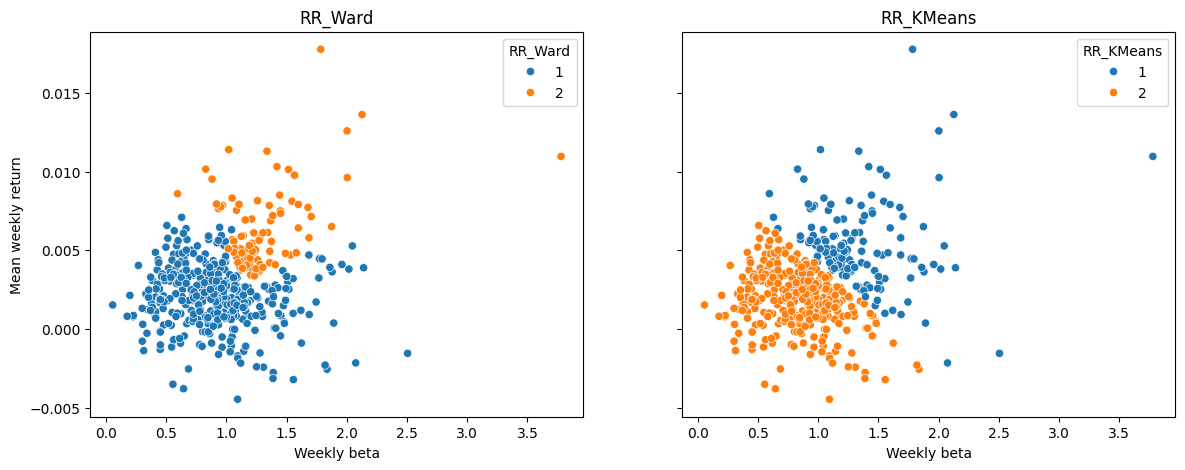

PCA explained variance: [0.458 0.336]


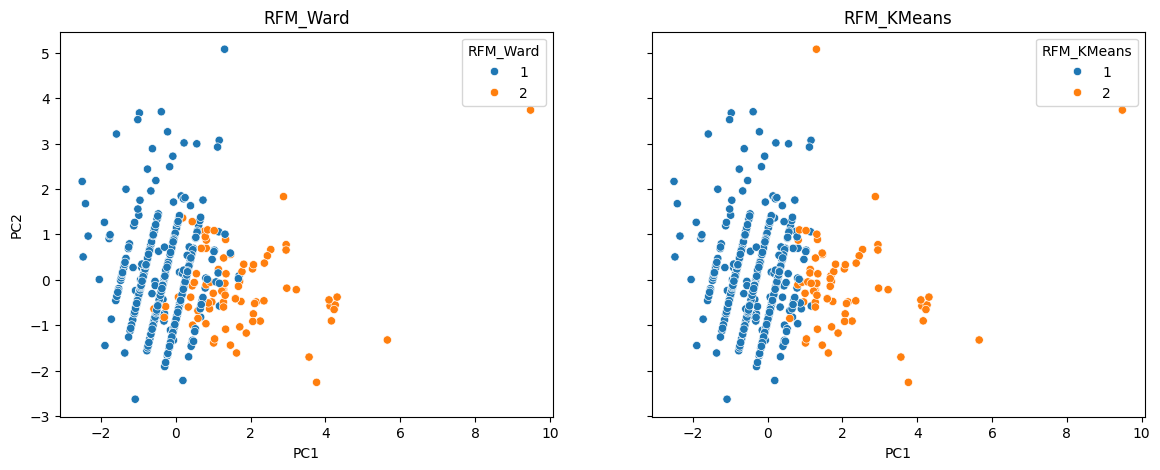

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, col in zip(axes, ['RR_Ward', 'RR_KMeans']):
    sns.scatterplot(data=features, x='Beta', y='Mean_Weekly_Return', hue=col, palette='tab10', ax=ax)
    ax.set(title=col, xlabel='Weekly beta', ylabel='Mean weekly return')
plt.show()

# RFM clusters (3 features, projected to 2 dimensions with PCA)
pca = PCA(n_components=2)
rfm_pca = pca.fit_transform(rfm_scaled)
print('PCA explained variance:', pca.explained_variance_ratio_.round(3))
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, col in zip(axes, ['RFM_Ward', 'RFM_KMeans']):
    sns.scatterplot(x=rfm_pca[:, 0], y=rfm_pca[:, 1], hue=features[col], palette='tab10', ax=ax)
    ax.set(title=col, xlabel='PC1', ylabel='PC2')
plt.show()

Compare Agglomerative and K-means Results

In [50]:
print('Weekly return and beta: Ward vs K-means ARI =', round(adjusted_rand_score(features['RR_Ward'], features['RR_KMeans']), 3))
print(pd.crosstab(features['RR_Ward'], features['RR_KMeans']))
print('\nRFM: Ward vs K-means ARI =', round(adjusted_rand_score(features['RFM_Ward'], features['RFM_KMeans']), 3))
print(pd.crosstab(features['RFM_Ward'], features['RFM_KMeans']))

Weekly return and beta: Ward vs K-means ARI = 0.598
RR_KMeans   1    2
RR_Ward           
1          51  343
2          92    0

RFM: Ward vs K-means ARI = 0.7
RFM_KMeans    1   2
RFM_Ward           
1           396   8
2            22  60


## 2.5 RFM sensitivity and correlated inputs
### 2.5.1 Correlation analysis

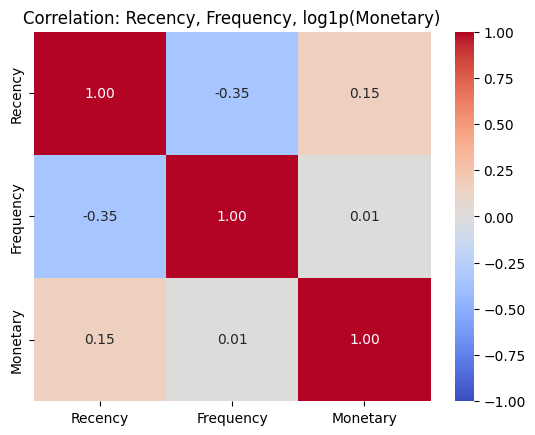

,Recency,Frequency,Monetary
Recency,1.000,-0.346,0.152
Frequency,-0.346,1.000,0.013
Monetary,0.152,0.013,1.000


In [51]:
rfm_corr = rfm.corr()
sns.heatmap(rfm_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation: Recency, Frequency, log1p(Monetary)')
plt.show()
rfm_corr.round(3)

### 2.5.2 Removal of Monetary

In [52]:
rf_scaled = StandardScaler().fit_transform(features[['Recency', 'Frequency']])
rf_hierarchy = linkage(rf_scaled, method='ward', metric='euclidean')
features['RF_Ward'] = cut_tree(rf_hierarchy, n_clusters=k_rfm_ward).ravel() + 1

print('Adjusted Rand index (RFM Ward vs RF Ward):', round(adjusted_rand_score(features['RFM_Ward'], features['RF_Ward']), 3))
print(pd.crosstab(features['RFM_Ward'], features['RF_Ward']))

#Traded value profiles of both solutions
for col in ['RFM_Ward', 'RF_Ward']:
    print('\n' + col)
    print(features.groupby(col)['Monetary'].agg(['count', 'mean', 'median']).div([1, 1e9, 1e9]).round(2)
          .rename(columns={'mean': 'mean_$bn', 'median': 'median_$bn'}))

Adjusted Rand index (RFM Ward vs RF Ward): 0.873
RF_Ward     1   2
RFM_Ward         
1         394  10
2           3  79

RFM_Ward
          count  mean_$bn  median_$bn
RFM_Ward                             
1         404.0     37.83       16.05
2          82.0     47.16       17.85

RF_Ward
         count  mean_$bn  median_$bn
RF_Ward                             
1        397.0     37.81       15.46
2         89.0     46.53       20.85


## 3.2 Cluster comparison and sector composition

Compare Cluster Assignments

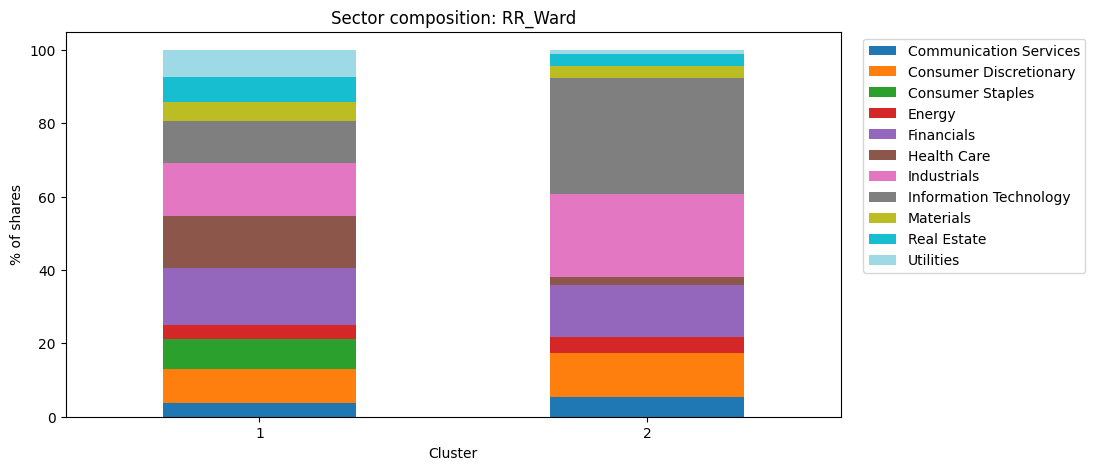

RR_Ward                    1     2
GICS Sector                       
Communication Services   3.8   5.4
Consumer Discretionary   9.1  12.0
Consumer Staples         8.1   0.0
Energy                   4.1   4.3
Financials              15.5  14.1
Health Care             14.2   2.2
Industrials             14.5  22.8
Information Technology  11.4  31.5
Materials                5.1   3.3
Real Estate              6.9   3.3
Utilities                7.4   1.1


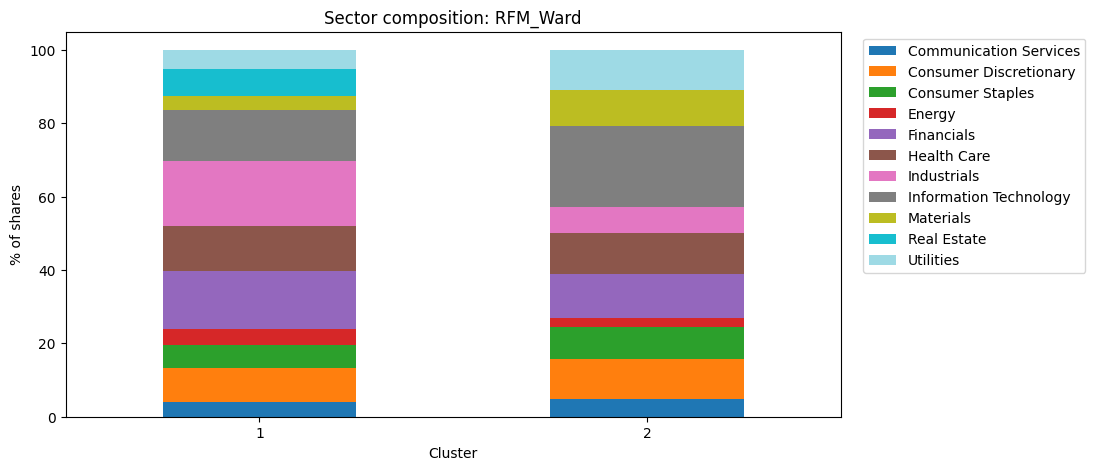

RFM_Ward                   1     2
GICS Sector                       
Communication Services   4.0   4.9
Consumer Discretionary   9.4  11.0
Consumer Staples         6.2   8.5
Energy                   4.5   2.4
Financials              15.8  12.2
Health Care             12.1  11.0
Industrials             17.8   7.3
Information Technology  13.9  22.0
Materials                3.7   9.8
Real Estate              7.4   0.0
Utilities                5.2  11.0


In [53]:
for col in ['RR_Ward', 'RFM_Ward']:
    sector_mix = pd.crosstab(features['GICS Sector'], features[col], normalize='columns') * 100
    sector_mix.T.plot(kind='bar', stacked=True, figsize=(10, 5), colormap='tab20', rot=0)
    plt.title('Sector composition: ' + col); plt.ylabel('% of shares'); plt.xlabel('Cluster')
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.show()
    print(sector_mix.round(1))

Analyse Sector Composition

In [54]:
print('ARI (RR_Ward vs RFM_Ward):', round(adjusted_rand_score(features['RR_Ward'], features['RFM_Ward']), 3))
pd.crosstab(features['RR_Ward'], features['RFM_Ward'], margins=True)

ARI (RR_Ward vs RFM_Ward): 0.029


RFM_Ward,1,2,All
RR_Ward,,,
1,331,63,394
2,73,19,92
All,404,82,486


Visualise Sector Distribution

In [55]:
corr = weekly_returns[features.index].corr()
groups = sorted(features['RR_Ward'].unique())
dependence = pd.DataFrame(index=groups, columns=groups, dtype=float)
for a in groups:
    for b in groups:
        block = corr.loc[features.index[features['RR_Ward'] == a], features.index[features['RR_Ward'] == b]].values
        dependence.loc[a, b] = block[~np.eye(len(block), dtype=bool)].mean() if a == b else block.mean()
dependence.round(3)

,1,2
1,0.297,0.296
2,0.296,0.374


## Save

In [56]:
features.to_csv('cluster_assignments.csv')
print('Saved feature_table.csv, cluster_assignments.csv, exclusion_log.csv and data snapshots')

Saved feature_table.csv, cluster_assignments.csv, exclusion_log.csv and data snapshots
